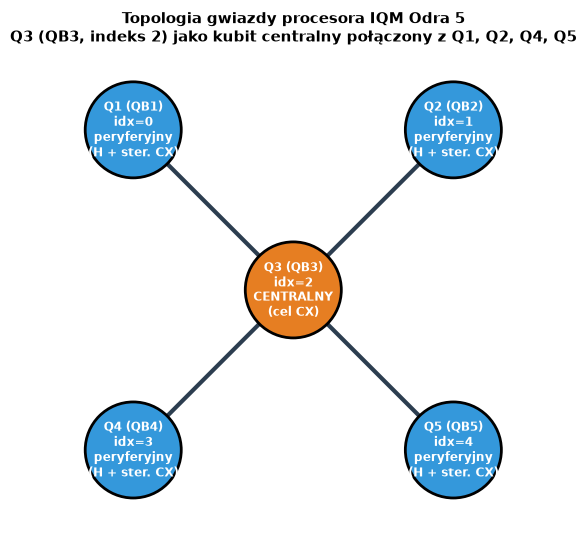


Obwód 3-kubitowy (Q3 centralny): Q3 = Q1 ^ Q2   (4 stanów poprawnych z 8)


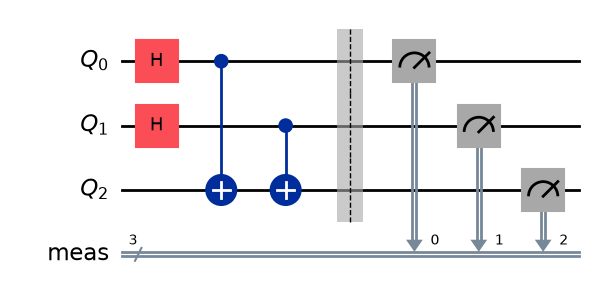

Głębokość: 4, bramki: {'measure': 3, 'h': 2, 'cx': 2, 'barrier': 1}

Obwód 4-kubitowy (Q3 centralny): Q3 = Q1 ^ Q2 ^ Q4   (8 stanów poprawnych z 16)


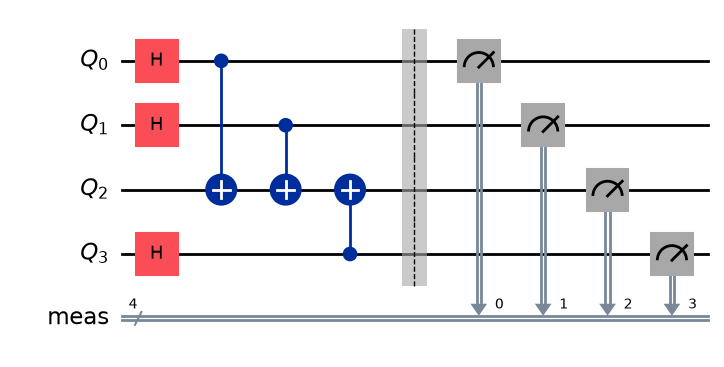

Głębokość: 5, bramki: {'measure': 4, 'h': 3, 'cx': 3, 'barrier': 1}

Obwód 5-kubitowy (Q3 centralny): Q3 = Q1 ^ Q2 ^ Q4 ^ Q5   (16 stanów poprawnych z 32)


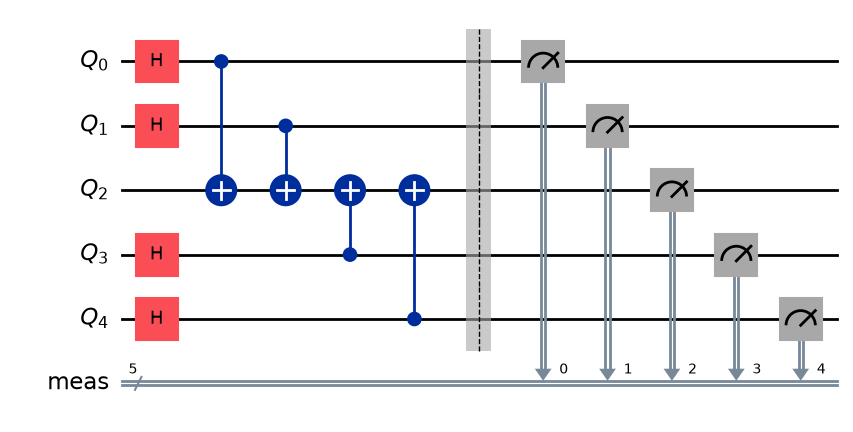

Głębokość: 6, bramki: {'measure': 5, 'h': 4, 'cx': 4, 'barrier': 1}


In [4]:
# ---- Komórka: mapa topologii IQM Odra 5 oraz obwody EQRNG (Q3 zawsze centralny) ----
import os
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from qiskit import QuantumCircuit, QuantumRegister, transpile

try:
    from IPython.display import display
except ImportError:          # uruchomienie poza Jupyterem
    display = print

# KONFIGURACJA
N_QUBITS_LIST = [3, 4, 5]    # które obwody narysować (np. [5] albo [3, 4, 5])
CENTER_QUBIT = 2             # indeks 2 -> Q3 (QB3) jest ZAWSZE kubitem centralnym Odry 5
SHOW_TRANSPILED = False      # True -> dodatkowo obwód po transpilacji na IQM Odra 5 (wymaga token.env)
ENV_FILE = "token.env"


def plot_odra5_topology():
    """Rysuje mapę topologii gwiazdy procesora IQM Odra 5 z kubitem Q3 (QB3) w centrum."""
    fig, ax = plt.subplots(figsize=(6, 5.5))
    ax.set_aspect("equal")
    ax.axis("off")

    # Pozycje kubitów: Q3 (indeks 2) w centrum, Q1, Q2, Q4, Q5 na obwodzie gwiazdy
    pos = {
        2: (0.0, 0.0),      # Q3 (QB3) - centralny
        0: (-1.0, 1.0),     # Q1 (QB1)
        1: (1.0, 1.0),      # Q2 (QB2)
        3: (-1.0, -1.0),    # Q4 (QB4)
        4: (1.0, -1.0),     # Q5 (QB5)
    }

    cx, cy = pos[CENTER_QUBIT]
    for idx, (x, y) in pos.items():
        if idx != CENTER_QUBIT:
            ax.plot([x, cx], [y, cy], color="#2c3e50", lw=3.0, zorder=1)

    for idx, (x, y) in pos.items():
        is_center = idx == CENTER_QUBIT
        color = "#e67e22" if is_center else "#3498db"
        role = "CENTRALNY\n(cel CX)" if is_center else "peryferyjny\n(H + ster. CX)"
        circle = Circle((x, y), 0.30, facecolor=color, edgecolor="black", lw=2.0, zorder=2)
        ax.add_patch(circle)
        ax.text(
            x, y, f"Q{idx + 1} (QB{idx + 1})\nidx={idx}\n{role}",
            ha="center", va="center", color="white", fontsize=8.5, fontweight="bold", zorder=3,
        )

    ax.set_xlim(-1.55, 1.55)
    ax.set_ylim(-1.50, 1.50)
    ax.set_title(
        "Topologia gwiazdy procesora IQM Odra 5\n"
        "Q3 (QB3, indeks 2) jako kubit centralny połączony z Q1, Q2, Q4, Q5",
        fontsize=11, fontweight="bold",
    )
    plt.tight_layout()
    fig.savefig("odra5_topology_map.png", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def build_eqrng_circuit(n: int, center: int = CENTER_QUBIT) -> QuantumCircuit:
    """
    n-kubitowy EQRNG dopasowany do topologii Odry 5:
      - kubit `center` (domyślnie indeks 2, czyli Q3) jest ZAWSZE kubitem centralnym (celem bramek CX),
      - wszystkie pozostałe kubity (i != center) mają bramki H i sterują bramkami CX(i, center),
      - zachowana jest reguła parzystości: Q3 = XOR pozostałych kubitów.
    """
    if n <= center:
        raise ValueError(f"Liczba kubitów n={n} musi być większa niż indeks centralny {center} (min. 3).")

    qreg = QuantumRegister(n, "Q")
    qc = QuantumCircuit(qreg, name=f"EQRNG_{n}q")
    peripherals = [i for i in range(n) if i != center]

    for i in peripherals:
        qc.h(i)
    for i in peripherals:
        qc.cx(i, center)

    qc.measure_all()
    return qc


def show_circuit(qc: QuantumCircuit, title: str):
    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)
    try:
        fig = qc.draw("mpl", fold=-1, style="iqp")
        display(fig)
        plt.close(fig)
    except Exception as exc:     # brak pylatexenc / matplotlib -> rysunek tekstowy
        print(f"[info] Rysunek mpl niedostępny ({exc}). Wersja tekstowa:")
        print(qc.draw("text", fold=-1))


def get_backend(env_path: str = ENV_FILE):
    import dotenv
    from iqm.qiskit_iqm import IQMProvider
    dotenv.load_dotenv(env_path, override=True)
    server_url = (
        os.getenv("IQM_SERVER_URL")
        or os.getenv("SERVER")
        or "https://odra5.e-science.pl/cocos"
    )
    token = os.getenv("IQM_TOKEN")
    if not token:
        raise ValueError(f"Nie znaleziono zmiennej IQM_TOKEN w pliku {env_path}!")
    os.environ["IQM_TOKEN"] = token
    return IQMProvider(server_url).get_backend()


# 1. Wyświetlenie mapy topologii IQM Odra 5 (Q3 w centrum)
plot_odra5_topology()

# 2. Opcjonalne połączenie z backendem Odra 5
backend = None
if SHOW_TRANSPILED:
    try:
        backend = get_backend()
        print(f"Połączono z backendem: {backend.name}")
    except Exception as exc:
        print(f"[BŁĄD] Nie udało się połączyć z Odra 5: {exc}\nPokazuję tylko obwody logiczne.")

# 3. Generowanie i wyświetlanie obwodów dla n = 3, 4, 5 (Q3 zawsze centralny)
for n in N_QUBITS_LIST:
    qc = build_eqrng_circuit(n, center=CENTER_QUBIT)
    peripherals_labels = " ^ ".join(f"Q{i + 1}" for i in range(n) if i != CENTER_QUBIT)

    show_circuit(
        qc,
        f"Obwód {n}-kubitowy (Q3 centralny): Q3 = {peripherals_labels} "
        f"  ({2 ** (n - 1)} stanów poprawnych z {2 ** n})",
    )
    print(f"Głębokość: {qc.depth()}, bramki: {dict(qc.count_ops())}")

    if backend is not None:
        try:
            # Mapowanie 1:1 [0, 1, 2, ...] gwarantuje, że Q3 (indeks 2) trafia na centralny QB3
            tqc = transpile(
                qc,
                backend=backend,
                initial_layout=list(range(n)),
                optimization_level=3,
            )
            show_circuit(tqc, f"Obwód {n}-kubitowy po transpilacji na {backend.name} (Q3 -> QB3 centralny)")
            print(f"Głębokość: {tqc.depth()}, bramki: {dict(tqc.count_ops())}")
            if tqc.layout is not None:
                phys = tqc.layout.initial_index_layout(filter_ancillas=True)
                names = (
                    [backend.index_to_qubit_name(p) for p in phys]
                    if hasattr(backend, "index_to_qubit_name") else phys
                )
                print("Mapowanie kubit logiczny -> fizyczny:")
                for i, p in enumerate(names):
                    role = "  <- KUBIT CENTRALNY (cel wszystkich bramek CX)" if i == CENTER_QUBIT else ""
                    print(f"  Q{i + 1} (idx {i}) -> {p}{role}")
            n_swap = tqc.count_ops().get("swap", 0)
            print(f"Bramki SWAP: {n_swap}")
        except Exception as exc:
            print(f"[BŁĄD] Transpilacja {n}-kubitowego obwodu nie powiodła się: {exc}")